In [ ]:
import numpy as np
import math

In [ ]:
import matplotlib.pyplot as plt

def plot_truss(nodes, members, *, ax=None, show_nodes=True,
               node_size=40, member_color="k",
               node_color="red", lw=1.5, equal_aspect=True):

    if ax is None:
        fig, ax = plt.subplots()

    # Plot members
    for i, j in members:
        x = [nodes[i][0], nodes[j][0]]
        y = [nodes[i][1], nodes[j][1]]
        ax.plot(x, y, member_color, lw=lw)

    # Plot nodes
    if show_nodes:
        xs = [n[0] for n in nodes]
        ys = [n[1] for n in nodes]
        ax.scatter(xs, ys, c=node_color, s=node_size, zorder=3)

    if equal_aspect:
        ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.grid(True, linestyle="--", alpha=0.4)

    return ax


In [ ]:
grid = (3, 1)

def generate_nodes(grid):
  origin = np.array([0, 0])
  nodes = np.zeros(((grid[0]+1) * (grid[1]+1), 2))
  nodes[0] = origin
  for r in range(grid[0]+1):
    for c in range(grid[1]+1):
      nodes[r * (grid[1]+1) + c] = origin + np.array([r, c])
  return nodes

In [ ]:
def slope(A, B, tol=1e-12):
    A = np.asarray(A)
    B = np.asarray(B)

    dx = B[0] - A[0]
    dy = B[1] - A[1]

    return np.inf if abs(dx) < tol else dy / dx

In [ ]:
def hypotenuse_set(n):
    hyp = set()

    for a in range(1, n):
        for b in range(a + 1, n):
            c2 = a*a + b*b
            c = int(math.isqrt(c2))   # safer than sqrt
            if c*c == c2 and c < n:
                hyp.add(c)

    return sorted(hyp)


In [ ]:
def dist(node1, node2):
  return np.linalg.norm(node1 - node2)

In [ ]:
def generate_connections(nodes):

  conns = []
  Lmax = int(np.round(np.sqrt(grid[0]**2 + grid[1]**2)))
  combos = math.comb(len(nodes), 2)
  hypos = hypotenuse_set(Lmax)
  for i in range(len(nodes)):
    for j in range(len(nodes)):
      m = slope(nodes[i], nodes[j])
      if i < j and (dist(nodes[i], nodes[j]) % 1 != 0 or ((int(np.round(dist(nodes[i], nodes[j]))) in hypos) and (m != 0 and m != np.inf)) or dist(nodes[i], nodes[j]) == 1):
        conns.append(np.array([i, j]))
  conns = np.array(conns)
  return conns



In [ ]:
def generate_ground_structure(grid, plot=False):
  n = generate_nodes(grid)
  c = generate_connections(n)
  if plot == True:
    plot_truss(n, c)
  return n, c

Number of Nodes: 8
Number of Bars: 22


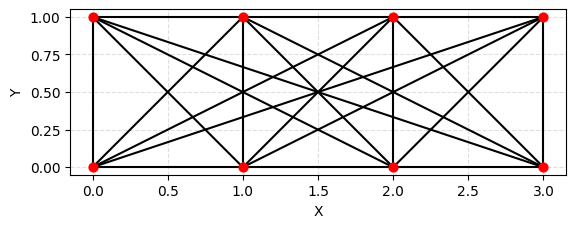

In [ ]:
nodes, bars = generate_ground_structure(grid, plot=True)
print(f"Number of Nodes: {len(nodes)}")
print(f"Number of Bars: {len(bars)}")

In [ ]:
from scipy.linalg import eigh
import numpy as np

def get_K(nodes, bars, A, E):
    nn = nodes.shape[0]
    ne = bars.shape[0]
    n_dof = 2 * nn
    delta = nodes[bars[:, 1], :] - nodes[bars[:, 0], :]
    length = np.sqrt((delta ** 2).sum(axis = 1))
    c = (delta.T / length).T                  # Direction Cosines
    ss = np.zeros([n_dof, n_dof])             # Initializing Global Stiffness Matrix
    for i in range(ne):
      aux = 2 * bars[i, :]
      index = np.r_[aux[0]:aux[0] + 2, aux[1]:aux[1] + 2]    # Getting the position of Element S.M. in Global S.M.

      # Element Stiffness
      x = c[i, 0]
      y = c[i, 1]
      t_bar = np.array([[x, y, 0, 0],
                        [0, 0, x, y]])

      k = E * (A[i] * 1e-4) / length[i] * np.array([[1, -1],
                                                    [-1, 1]])
      ke = t_bar.T @ k @ t_bar
      ss[np.ix_(index, index)] += ke     # Assembling the Global Matrices

    return ss

In [ ]:
def get_displacements(K, f, dofs, disp_at):
  ff = f[dofs]
  kff = K[np.ix_(dofs, dofs)]
  u = np.linalg.solve(kff, ff) * 1000  # mm
  u_full = np.zeros((K.shape[0], 1))
  u_full[dofs] = u
  return u_full[disp_at]


In [ ]:
E = 2.1e11  # N/m2
A = np.ones([len(bars)]) * 40 # cm2
fixed = np.array([0, 1, 2, 3])
dofs = [i for i in range(2*len(nodes)) if i not in fixed]
f0 = 1e5  # N
f = np.zeros((2*len(nodes), 1))
f[12] = f0
K = get_K(nodes, bars, A, E)
u = get_displacements(K, f, dofs, 12)   # mm
print(u)

[0.24308673]


In [ ]:
bars

array([[0, 1],
       [0, 2],
       [0, 3],
       [0, 5],
       [0, 7],
       [1, 2],
       [1, 3],
       [1, 4],
       [1, 6],
       [2, 3],
       [2, 4],
       [2, 5],
       [2, 7],
       [3, 4],
       [3, 5],
       [3, 6],
       [4, 5],
       [4, 6],
       [4, 7],
       [5, 6],
       [5, 7],
       [6, 7]])

In [ ]:
nodes

array([[0., 0.],
       [0., 1.],
       [1., 0.],
       [1., 1.],
       [2., 0.],
       [2., 1.],
       [3., 0.],
       [3., 1.]])

In [ ]:
np.random.seed(102)
idx = np.random.randint(len(bars))
new_bars = np.delete(bars, idx, axis=0)


[0.24308673]


<Axes: xlabel='X', ylabel='Y'>

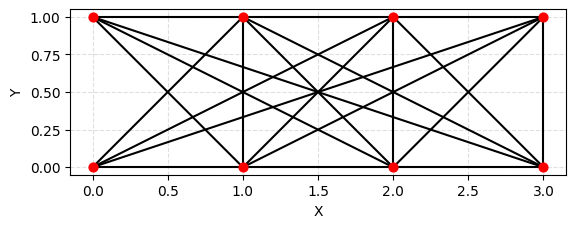

In [ ]:
K = get_K(nodes, new_bars, A, E)
u = get_displacements(K, f, dofs, 12)   # mm
print(u)
plot_truss(nodes, new_bars)

In [ ]:
np.random.seed(2)
idx = np.random.randint(len(new_bars))
new_new_bars = np.delete(new_bars, idx, axis=0)

[0.24910932]


<Axes: xlabel='X', ylabel='Y'>

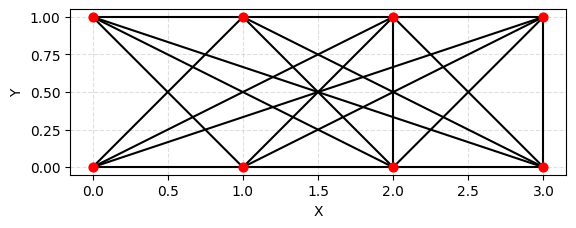

In [ ]:
K = get_K(nodes, new_new_bars, A, E)
u = get_displacements(K, f, dofs, 12)   # mm
print(u)
plot_truss(nodes, new_new_bars)
